# Semana 2: Uso de Pandas, Numpy y Matplotlib

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Crear un arreglo a partir de una lista

In [62]:
# Crear un arreglo a partir de una lista
arr = np.array([1, 2, 3, 4, 5])
print(arr)

[1 2 3 4 5]


Operaciones matemáticas sobre vectores numpy

In [64]:
a = np.array([1, 2, 3,7,8,9])
b = np.array([4, 5, 6,10,11,12])

suma = a + b
resta = a - b
multiplicacion = a * b  # Multiplicación elemento por elemento

print("Suma:", suma)
print("Resta:", resta)
print("Multiplicación:", multiplicacion)

Suma: [ 5  7  9 17 19 21]
Resta: [-3 -3 -3 -3 -3 -3]
Multiplicación: [  4  10  18  70  88 108]


Cambiar de dimensión

In [65]:
matriz = a.reshape(3, 2)  # Convertir en matriz 3x3
print(matriz)

[[1 2]
 [3 7]
 [8 9]]


In [60]:
# Leer datos desde el archivo CSV
df = pd.read_csv('ventas_500_datos.csv')

Se usa head para ver los primeros N elementos y tail los N últimos

In [61]:
df.head(8)

,Fecha,Producto,Region,Ventas,Precio
0,2024-01-01,Producto C,Sur,60,38
1,2024-01-02,Producto A,Sur,412,37
2,2024-01-03,Producto C,Este,286,20
3,2024-01-04,Producto C,Sur,14,97
4,2024-01-05,Producto A,Oeste,475,66
5,2024-01-06,Producto A,Norte,101,85
6,2024-01-07,Producto C,Oeste,179,57
7,2024-01-08,Producto B,Norte,326,70


In [13]:
df.tail(3)

,Fecha,Producto,Region,Ventas,Precio
497,2025-05-12,Producto A,Sur,295,82
498,2025-05-13,Producto B,Norte,153,21
499,2025-05-14,Producto C,Sur,433,91


El comando **describe** permite obtener métricas rapidas y conocidas sobre los datos estudiados siempre que sean numéricos

In [14]:
# 1. **Análisis descriptivo**
print("Estadísticas descriptivas del dataset:")
print(df.describe())

Estadísticas descriptivas del dataset:
           Ventas      Precio
count  500.000000  500.000000
mean   246.580000   58.474000
std    142.312365   22.827429
min     10.000000   20.000000
25%    121.750000   38.000000
50%    246.500000   58.000000
75%    365.000000   78.000000
max    495.000000   99.000000


El comando **groupby** permite hacer sumas parciales agrupando por columnas de los elementos

el comando **sum** permite sumar valores numeros de las columnas

In [19]:
# 3. **Agrupación mensual**
ventas_region = df.groupby('Region')['Ventas'].sum()
print("\nVentas totales por región:")
print(ventas_mensuales)


Ventas totales por región:
Region
Este     27844
Norte    37754
Oeste    31204
Sur      26488
Name: Ventas, dtype: int64


el comando **count** permite contar valores numeros de las columnas

In [40]:
Producto_region = df.groupby('Region')['Producto'].count()
print("\nVentas totales por región:")
print(Producto_region)


Ventas totales por región:
Region
Este     117
Norte    148
Oeste    120
Sur      115
Name: Producto, dtype: int64


Pero no siempre es facil realizar estos agrupamientos dado que no todos los factores de agrupación estan explicitamente en las columnas

In [17]:
## trabajar en el agrupamiento por meses esto debe ser extraido de la columna fecha
df['Fecha'] = pd.to_datetime(df['Fecha'])  # Asegurar que la columna Fecha sea de tipo datetime
df['Mes'] = df['Fecha'].dt.month

Ver que ha pasado con la cantidad de columnas

In [18]:
df.head(2)

,Fecha,Producto,Region,Ventas,Precio,Mes
0,2024-01-01,Producto C,Sur,60,38,1
1,2024-01-02,Producto A,Sur,412,37,1


In [21]:
ventas_mensuales = df.groupby('Mes')['Ventas'].sum()
print("\nVentas totales por mes:")
print(ventas_mensuales)


Ventas totales por mes:
Mes
1     14996
2     14406
3     15371
4     13892
5     12339
6      7695
7      6315
8      8739
9      7254
10     7416
11     8362
12     6505
Name: Ventas, dtype: int64


In [37]:
producto_mas_rentable = df.groupby('Producto')['Ventas'].sum().idxmax()
region_mas_rentable = df.groupby('Region')['Ventas'].sum().idxmax()
print(f"\nEl producto más rentable es: {producto_mas_rentable}")
print(f"La región más rentable es: {region_mas_rentable}")


El producto más rentable es: Producto C
La región más rentable es: Norte


El análisis de correlación en Python te ayuda a entender la relación lineal entre variables numéricas. Aquí te muestro cómo realizarlo paso a paso:

In [23]:
correlacion = df[['Ventas', 'Precio']].corr()
print("\nCorrelación entre Ventas y Precio:")
print(correlacion)


Correlación entre Ventas y Precio:
          Ventas    Precio
Ventas  1.000000 -0.015586
Precio -0.015586  1.000000


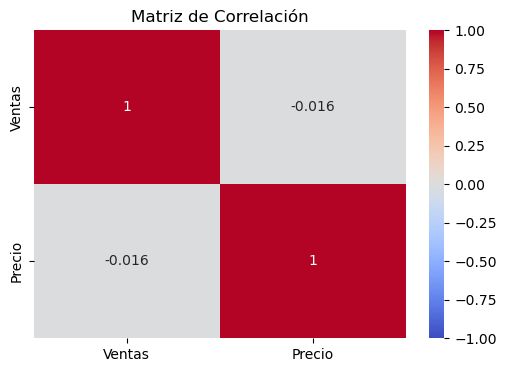

In [26]:
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de Correlación")
plt.show()

Los gráficos nos muestran una gran cantidad de información de manera más clara **matplotlib** permite hacer una gran variedad de gráficas

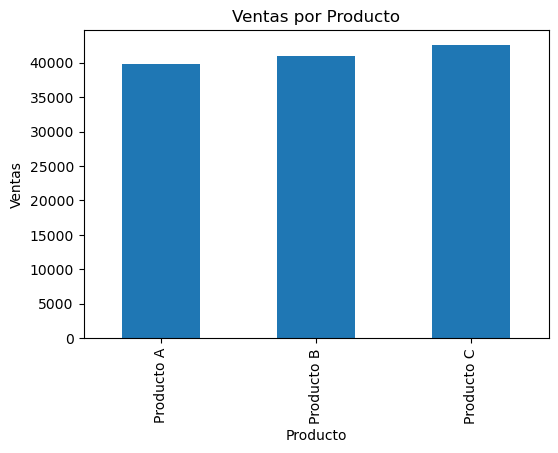

In [29]:
## mostrar la cantidad de ventas por producto
plt.figure(figsize=(6, 4))
ventas_producto = df.groupby('Producto')['Ventas'].sum()
ventas_producto.plot(kind='bar', title='Ventas por Producto')
plt.ylabel('Ventas')
plt.show()

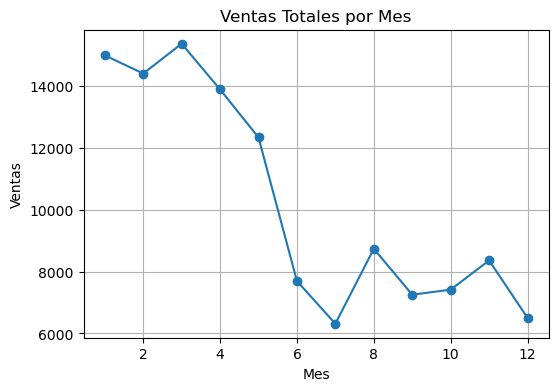

In [31]:
## mostrar una grafica de ventas por mes para evaluar caidas o subidas
plt.figure(figsize=(6, 4))
ventas_mensuales.plot(kind='line', marker='o', title='Ventas Totales por Mes')
plt.ylabel('Ventas')
plt.xlabel('Mes')
plt.grid()
plt.show()

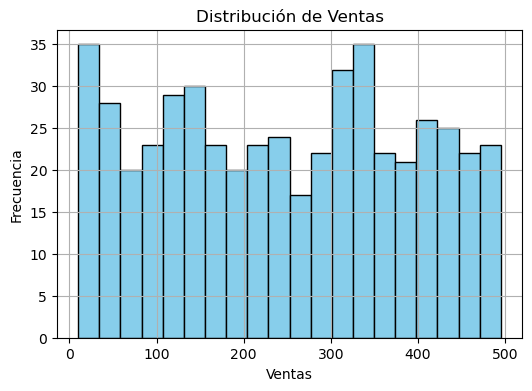

In [36]:
plt.figure(figsize=(6,4))
plt.hist(df['Ventas'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribución de Ventas')
plt.xlabel('Ventas')
plt.ylabel('Frecuencia')
plt.grid()
plt.show()

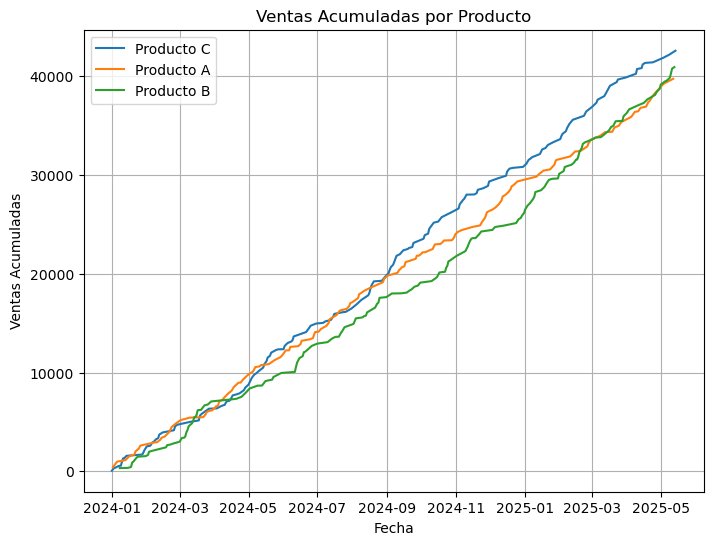

In [41]:
## calcular las ventas acumuladas por producto
df['Ventas_Acumuladas'] = df.groupby('Producto')['Ventas'].cumsum()

plt.figure(figsize=(8, 6))
for producto in df['Producto'].unique():
    datos_producto = df[df['Producto'] == producto]
    plt.plot(datos_producto['Fecha'], datos_producto['Ventas_Acumuladas'], label=producto)
plt.title('Ventas Acumuladas por Producto')
plt.xlabel('Fecha')
plt.ylabel('Ventas Acumuladas')
plt.legend()
plt.grid()
plt.show()

In [48]:
ventas_producto_este = df[df['Region'] == 'Este'].groupby('Producto')['Ventas'].sum()
print("\nVentas totales por región:")
print(ventas_producto_este)


Ventas totales por región:
Producto
Producto A    9216
Producto B    9911
Producto C    8717
Name: Ventas, dtype: int64


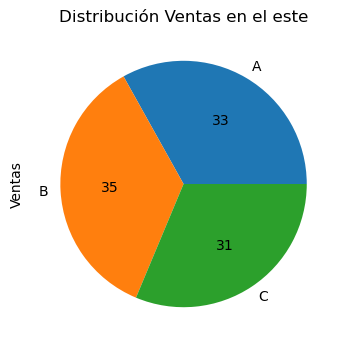

In [55]:
plt.figure(figsize=(6, 4))
etiquetas=['A','B','C']
plt.pie(ventas_producto_este,labels=etiquetas,autopct='%d')
plt.title("Distribución Ventas en el este")
plt.ylabel('Ventas')
plt.show()

### Ejercicios adicionales como tarea

1. Mostrar las ventas por region utilizando un gráfico de barras

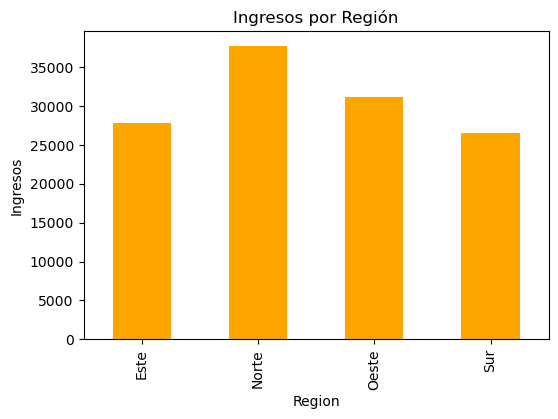

In [34]:
plt.figure(figsize=(6,4))
ingresos_region = df.groupby('Region')['Ventas'].sum()
ingresos_region.plot(kind='bar', color='orange', title='Ingresos por Región')
plt.ylabel('Ingresos')
plt.show()

2. Mostrar el mes como la menor monto en ventas, usar el comando _idxmin_

In [39]:
mes_menos_rentable = df.groupby('Mes')['Ventas'].sum().idxmin()
print(f"El mes menos rentable es: {mes_menos_rentable}")

El mes menos rentable es: 7


3.  Hacer un gráfico de PIE de las ventas por Region del **Producto A**

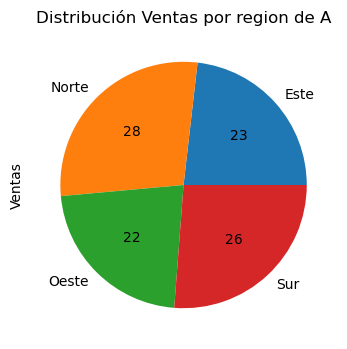

In [58]:
ventas_region_A = df[df['Producto'] == 'Producto A'].groupby('Region')['Ventas'].sum()
plt.figure(figsize=(6, 4))
etiquetas=['Este','Norte','Oeste','Sur']
plt.pie(ventas_region_A,labels=etiquetas,autopct='%d')
plt.title("Distribución Ventas por region de A")
plt.ylabel('Ventas')
plt.show()

4. Implementar 5 resultados diversos que se puede lograr con cualquiera de las 3 librerias usando más comandos adiciones, para ello investigar un poco de dichas librerias